[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/05-deep-learning/notebooks/04-overfitting-dropout-early-stopping.ipynb)

# 05-04 · Overfitting, dropout and early stopping

**Goal:** make a network **overfit** on purpose, see it in the loss curves, then fix it with two tools:
- **dropout** — randomly switching off neurons during training,
- **early stopping** — stopping when validation loss stops improving and keeping the best weights.

To make overfitting obvious we deliberately train a large MLP on only **200** training images for many epochs. Runs in under a minute on CPU.

## Setup: device and reproducibility

- `device` is `"cuda"` if a GPU is available (e.g. Colab with a T4 GPU), otherwise `"cpu"`. All later code uses this variable, so the same notebook runs anywhere.
- `torch.manual_seed(0)` fixes the random starting weights so you get the same results each run.
- On CPU we use one thread: these models are tiny, and many threads fighting over tiny jobs is slower (especially on shared or busy machines).

In [1]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(1)
torch.manual_seed(0)
print("PyTorch", torch.__version__, "| running on:", device)

PyTorch 2.15.0+cpu | running on: cpu


## Load the digits and make tensors

`load_digits` ships inside scikit-learn: 1,797 greyscale images of handwritten digits, each 8×8 pixels with values 0–16.

1. Divide by 16 so pixels are between 0 and 1 (neural networks train best on small, similar-sized inputs).
2. Split into **train** (60%), **validation** (20%, for watching overfitting) and **test** (20%, locked away until the end).
3. Convert to tensors: inputs as `float32`, labels as `long` (whole numbers), which `CrossEntropyLoss` requires.

In [2]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.data.astype("float32") / 16.0          # shape (1797, 64), values 0..1
y = digits.target                                 # shape (1797,), values 0..9

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25,
                                                  random_state=0, stratify=y_trainval)

X_train_t, X_val_t, X_test_t = (torch.tensor(a) for a in (X_train, X_val, X_test))
y_train_t, y_val_t, y_test_t = (torch.tensor(a, dtype=torch.long) for a in (y_train, y_val, y_test))
print("train", tuple(X_train_t.shape), "val", tuple(X_val_t.shape), "test", tuple(X_test_t.shape))

train (1077, 64) val (360, 64) test (360, 64)


## A small training set and a big model

We keep only the first 200 training images. With ~100,000 parameters and 200 examples, the network can memorise every training image — a recipe for overfitting.

In [3]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import copy

X_small, y_small = X_train_t[:200], y_train_t[:200]

def make_mlp(dropout=0.0):
    return nn.Sequential(
        nn.Linear(64, 256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 10),
    )
print("parameters:", sum(p.numel() for p in make_mlp().parameters()), "for", len(X_small), "training images")

parameters: 85002 for 200 training images


## A training function that records both losses

Same loop as before. It optionally does **early stopping**: if validation loss has not improved for `patience` epochs, stop, and restore the best weights we saw. `copy.deepcopy(model.state_dict())` takes a snapshot of the weights.

In [4]:
def train(model, epochs=150, lr=1e-3, patience=None, weight_decay=0.0):
    loader = DataLoader(TensorDataset(X_small, y_small), batch_size=32, shuffle=True)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train": [], "val": []}
    best_val, best_state, best_epoch, waited = float("inf"), None, 0, 0
    for epoch in range(epochs):
        model.train(); total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(xb)
        hist["train"].append(total / len(X_small))
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val_t.to(device)), y_val_t.to(device)).item()
        hist["val"].append(val_loss)
        if val_loss < best_val:                                   # new best: remember it
            best_val, best_epoch, waited = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1
            if patience is not None and waited >= patience:       # no improvement for a while: stop
                print(f"early stop at epoch {epoch}, best epoch was {best_epoch}")
                break
    if patience is not None:
        model.load_state_dict(best_state)                         # roll back to the best weights
    return hist, best_epoch

def test_acc(model):
    model.eval()
    with torch.no_grad():
        return (model(X_test_t.to(device)).argmax(1) == y_test_t.to(device)).float().mean().item()

## Experiment 1 · No protection

Watch the two curves: training loss goes almost to zero (memorised), while validation loss bottoms out early and then **climbs**.

lowest val loss at epoch 35; final train loss 0.0008, final val loss 0.276
test accuracy (weights from the last epoch): 0.922


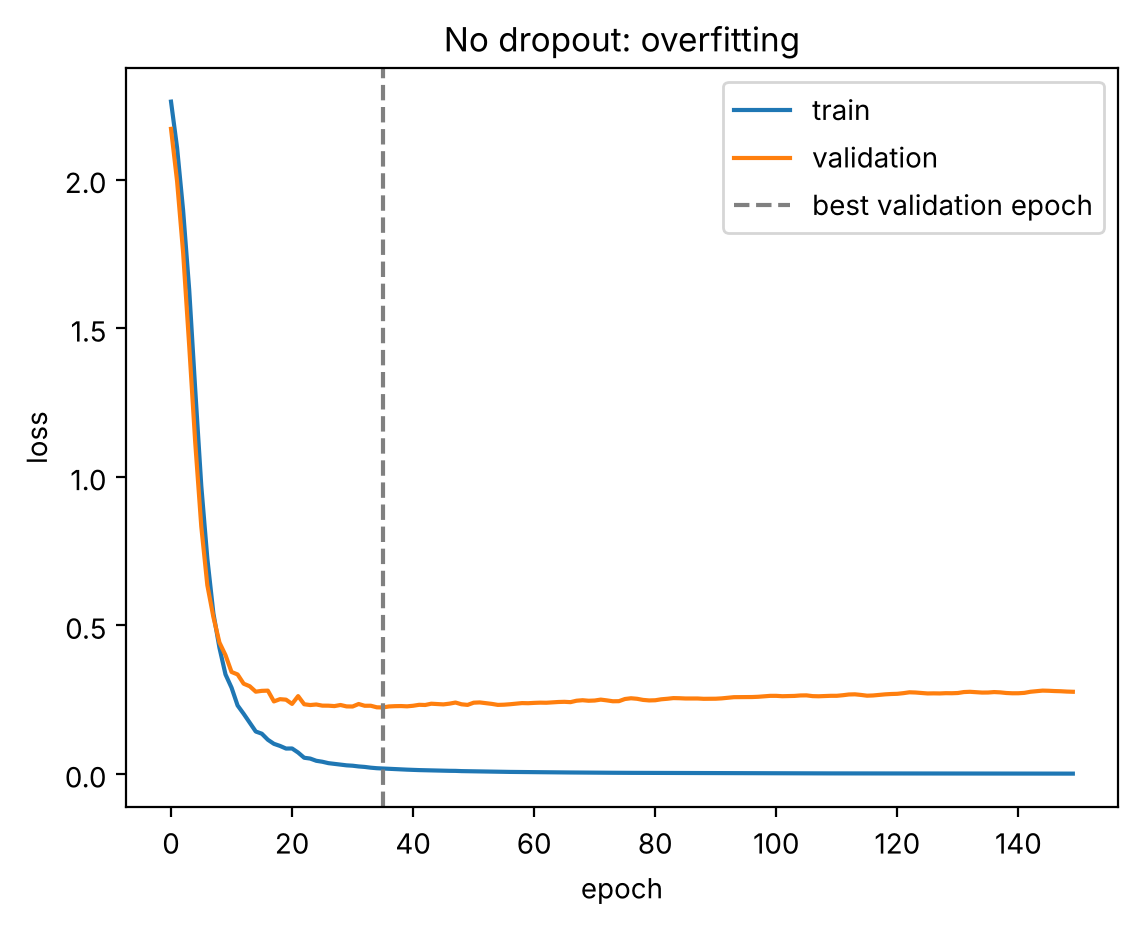

In [5]:
torch.manual_seed(0)
plain = make_mlp(dropout=0.0).to(device)
plain_hist, plain_best = train(plain)
print(f"lowest val loss at epoch {plain_best}; final train loss {plain_hist['train'][-1]:.4f}, "
      f"final val loss {plain_hist['val'][-1]:.3f}")
print("test accuracy (weights from the last epoch):", round(test_acc(plain), 3))

plt.plot(plain_hist["train"], label="train"); plt.plot(plain_hist["val"], label="validation")
plt.axvline(plain_best, color="grey", ls="--", label="best validation epoch")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("No dropout: overfitting"); plt.legend(); plt.show()

## Experiment 2 · Dropout

Same model with `Dropout(0.5)` after each hidden layer: half of the hidden values are switched off at random on every batch during training. Remember: dropout is only active in `model.train()` mode; `model.eval()` turns it off.

In [6]:
torch.manual_seed(0)
drop = make_mlp(dropout=0.5).to(device)
drop_hist, drop_best = train(drop)
print(f"final val loss {drop_hist['val'][-1]:.3f} (no dropout: {plain_hist['val'][-1]:.3f})")
print("test accuracy:", round(test_acc(drop), 3))

final val loss 0.205 (no dropout: 0.276)
test accuracy: 0.939


Dropout in action: in training mode, the same input gives **different** outputs each time (different neurons are dropped). In eval mode, outputs are stable.

In [7]:
x1 = X_val_t[:1].to(device)
drop.train()
print("train mode:", [drop(x1).argmax(1).item() for _ in range(5)], [round(drop(x1).max().item(), 2) for _ in range(5)])
drop.eval()
print("eval mode: ", [drop(x1).argmax(1).item() for _ in range(5)], [round(drop(x1).max().item(), 2) for _ in range(5)])

train mode: [5, 5, 5, 5, 5] [20.81, 16.0, 17.08, 15.11, 16.58]
eval mode:  [5, 5, 5, 5, 5] [16.39, 16.39, 16.39, 16.39, 16.39]


## Experiment 3 · Early stopping (+ a little weight decay)

No dropout this time. Instead we stop when validation loss has not improved for 10 epochs (`patience=10`), and roll back to the best weights. We also add `weight_decay=0.01` — a penalty that keeps weights small.

In [8]:
torch.manual_seed(0)
early = make_mlp(dropout=0.0).to(device)
early_hist, early_best = train(early, patience=10, weight_decay=0.01)
print("test accuracy (best weights restored):", round(test_acc(early), 3))

early stop at epoch 45, best epoch was 35
test accuracy (best weights restored): 0.931


## Compare all three

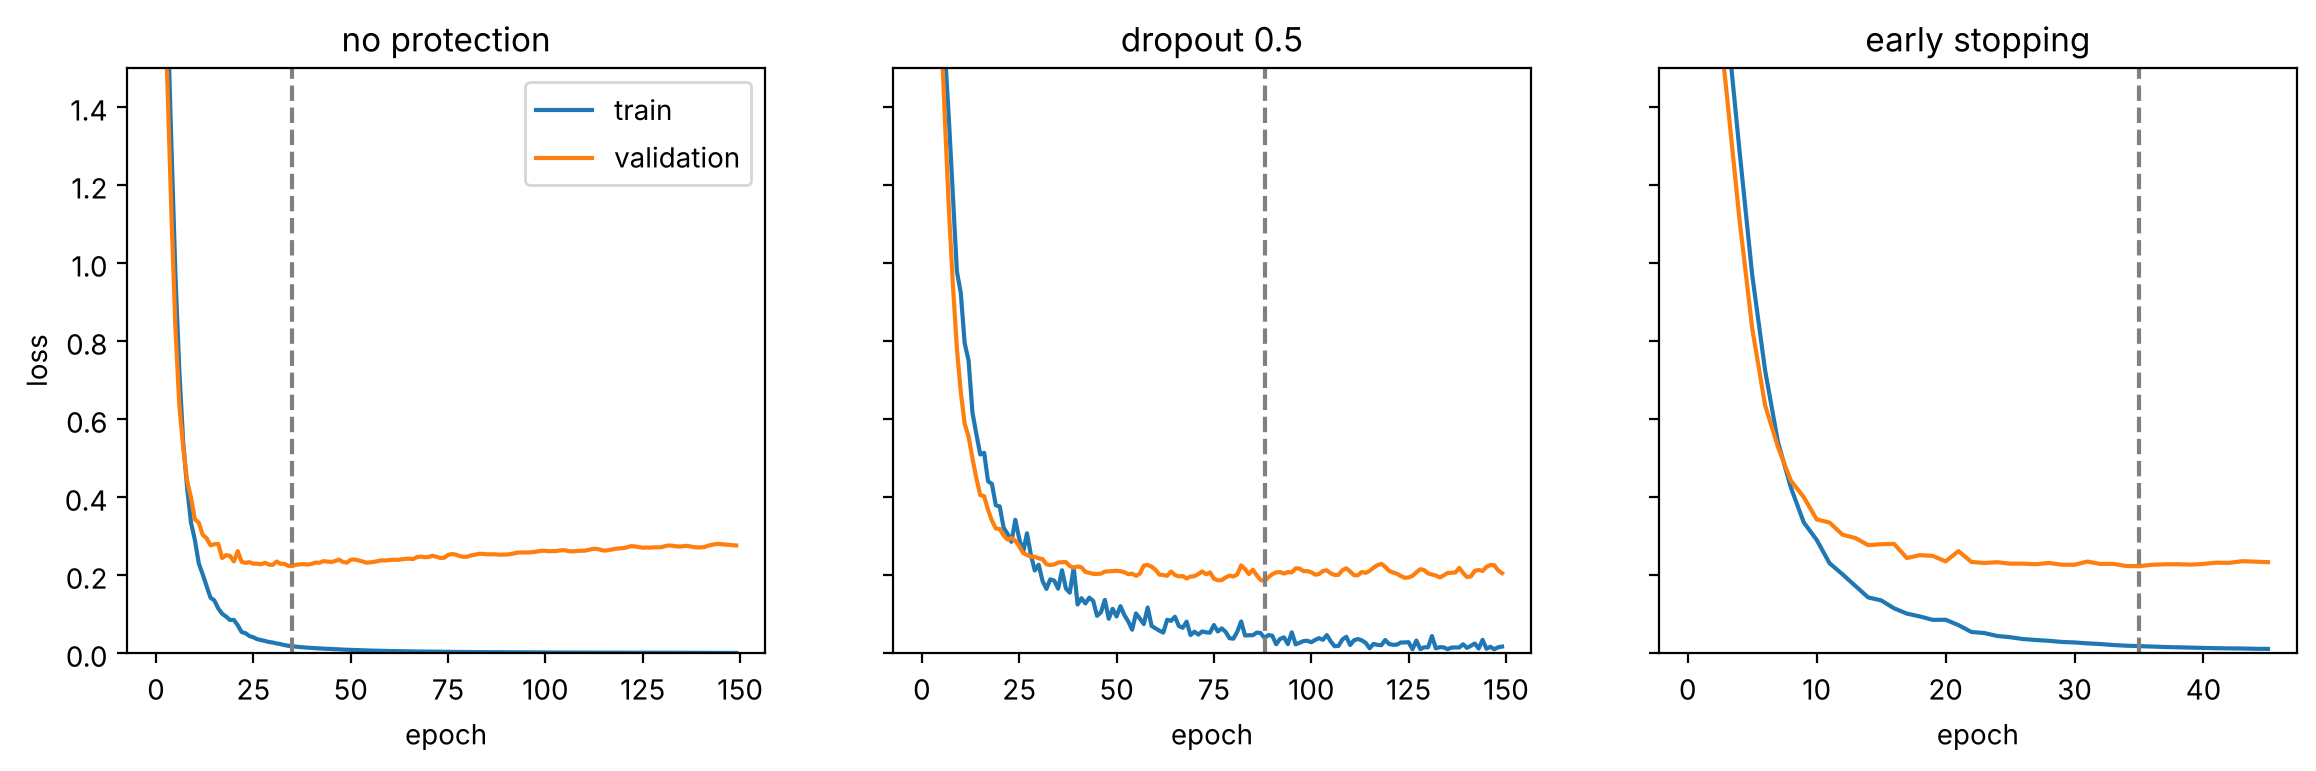

no protection   test acc 0.922
dropout 0.5     test acc 0.939
early stopping  test acc 0.931


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (name, h, b) in zip(axes, [("no protection", plain_hist, plain_best),
                                   ("dropout 0.5", drop_hist, drop_best),
                                   ("early stopping", early_hist, early_best)]):
    ax.plot(h["train"], label="train"); ax.plot(h["val"], label="validation")
    ax.axvline(b, color="grey", ls="--"); ax.set_title(name); ax.set_xlabel("epoch")
axes[0].set_ylabel("loss"); axes[0].legend(); axes[0].set_ylim(0, 1.5)
plt.show()

print(f"{'no protection':15s} test acc {test_acc(plain):.3f}")
print(f"{'dropout 0.5':15s} test acc {test_acc(drop):.3f}")
print(f"{'early stopping':15s} test acc {test_acc(early):.3f}")

**How to read this.** Without protection, validation loss rises after its best epoch — the network grows over-confident on wrong answers. Dropout keeps the validation loss lower and flatter. Early stopping simply stops near the best point and keeps those weights, and it saves training time too. Exact accuracies will vary a little between machines, but the *shape* of the curves is the lesson.

The biggest fix of all is usually **more data**: train on all ~1,000 training images instead of 200 and the overfitting gap shrinks a lot (try it in the exercises).

## Saving a checkpoint

A **checkpoint** stores everything needed to resume training later: model weights, optimizer state and the epoch. Here we save the early-stopped model's weights plus some notes to a temp folder.

In [10]:
import os, tempfile
ckpt = {"model_state": early.state_dict(), "best_epoch": early_best, "note": "MLP 64-256-256-10, 200 train images"}
path = os.path.join(tempfile.gettempdir(), "early_stopped.pt")
torch.save(ckpt, path)
loaded = torch.load(path, map_location=device)
restored = make_mlp().to(device); restored.load_state_dict(loaded["model_state"])
print("restored test accuracy:", round(test_acc(restored), 3), "| best epoch:", loaded["best_epoch"])

restored test accuracy: 0.931 | best epoch: 35


## Recap

- Overfitting shows up as validation loss rising while training loss keeps falling.
- **Dropout** randomly disables neurons in training → more robust network. Always call `model.eval()` before evaluating.
- **Early stopping** with patience → stop at the best epoch and restore its weights.
- **Weight decay** (via `AdamW`) keeps weights small.
- More data beats every trick.